# Exploratory Prediction of Reported STEM Interest

This notebook compares supervised-learning models that predict reported
STEM interest using selected pre-event survey characteristics.

The target is:

- 0: original STEM-interest ratings 1–3
- 1: original STEM-interest ratings 4–5

Class 0 does not mean "uninterested".

This experiment predicts a contemporaneous survey response. It does not
predict future STEM careers or measure the event's effect.

Unresolved duplicate candidates are excluded from this preliminary
experiment. This exclusion may affect representativeness.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import StratifiedGroupKFold

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from sklearn.inspection import permutation_importance


current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data" / "cleaned").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot locate data/cleaned.")

CLEANED = ROOT / "data" / "cleaned"
MODEL_TABLES = ROOT / "outputs" / "tables" / "student_models"
MODEL_FIGURES = ROOT / "outputs" / "figures" / "student_models"
MODELS = ROOT / "outputs" / "models"

for folder in [MODEL_TABLES, MODEL_FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

SEED = 42

df = pd.read_excel(
    CLEANED / "students_pre_event_standardized.xlsx",
    sheet_name="Standardized Data",
    keep_default_na=False,
    na_values=[""],
)

## 1. Define the Modeling Sample and Target

Exclude unresolved duplicate candidates, records without a school group,
and records without a valid target rating.

Missing target values are not imputed.

Record all exclusions. Technology conflicts do not remove the entire
student record; the affected technology predictors remain missing.

,class,definition,count,percent
0,0,Ratings 1–3,64,28.959276
1,1,Ratings 4–5,157,71.040724


Input submissions: 241
Included in preliminary model: 221
Excluded: 20
School groups: 42


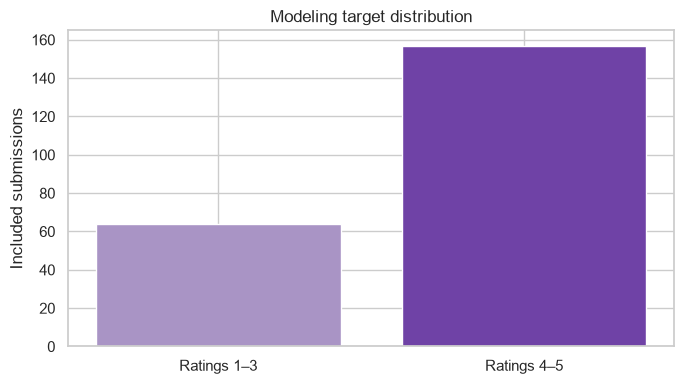

In [2]:
def boolean_flag(series):
    normalized = series.astype("string").str.strip().str.casefold()

    mapping = {
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "1.0": True,
        "0.0": False,
    }

    unexpected = normalized.notna() & ~normalized.isin(mapping)

    if unexpected.any():
        raise ValueError("Unexpected Boolean flag values.")

    return normalized.map(mapping).astype("boolean")


duplicate_flag = boolean_flag(df["possible_duplicate"])

# Missing duplicate-review status is also unresolved.
unresolved_duplicate = duplicate_flag.fillna(True)

target_rating = pd.to_numeric(
    df["stem_interest"],
    errors="coerce",
)

valid_target = target_rating.isin([1, 2, 3, 4, 5])
valid_school = df["school_key"].notna()

eligible = (
    ~unresolved_duplicate
    & valid_target
    & valid_school
)

sample_audit = df[["response_id"]].copy()
sample_audit["unresolved_duplicate"] = unresolved_duplicate
sample_audit["missing_or_invalid_target"] = ~valid_target
sample_audit["missing_school_group"] = ~valid_school
sample_audit["included_in_model"] = eligible

sample_audit.to_csv(
    MODEL_TABLES / "model_sample_audit.csv",
    index=False,
)

model_df = df.loc[eligible].copy().reset_index(drop=True)

y = (
    pd.to_numeric(model_df["stem_interest"]) >= 4
).astype(int)

groups = model_df["school_key"].astype(str)

class_counts = y.value_counts().reindex([0, 1], fill_value=0)

class_table = pd.DataFrame({
    "class": [0, 1],
    "definition": ["Ratings 1–3", "Ratings 4–5"],
    "count": class_counts.to_numpy(),
})

class_table["percent"] = (
    class_table["count"] / len(model_df) * 100
)

display(class_table)

print("Input submissions:", len(df))
print("Included in preliminary model:", len(model_df))
print("Excluded:", int((~eligible).sum()))
print("School groups:", groups.nunique())

if y.nunique() != 2:
    raise ValueError("Both target classes are required.")

class_table.to_csv(
    MODEL_TABLES / "target_distribution.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    class_table["definition"],
    class_table["count"],
    color=["#A994C5", "#6F42A6"],
)

ax.set_title("Modeling target distribution")
ax.set_ylabel("Included submissions")

fig.tight_layout()
fig.savefig(
    MODEL_FIGURES / "target_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

## 2. Select Predictors and Define Preprocessing

Exclude identifiers, school identifiers, accommodation information,
review flags, the target, and fields derived from the target.

Use a modest predictor set.

Numeric predictors are median-imputed and scaled. Binary technology
indicators are imputed using the most frequent training value.
Categorical predictors are one-hot encoded.

All learned preprocessing is fitted inside each training fold.

In [3]:
numeric_features = [
    "grade_numeric",
    "ct_familiarity_score",
    "ct_decomposition",
    "ct_patterns",
    "ct_steps",
    "ct_iteration",
    "ct_application",
]

binary_features = [
    "selected_ai",
    "selected_scratch",
    "selected_python",
    "selected_microbit",
    "selected_arduino",
    "selected_climate_kit",
]

categorical_features = [
    "project_experience",
]

FEATURES = (
    numeric_features
    + binary_features
    + categorical_features
)

X = model_df[FEATURES].copy()

for column in numeric_features + binary_features:
    X[column] = pd.to_numeric(
        X[column],
        errors="coerce",
    ).astype(float)

for column in categorical_features:
    X[column] = X[column].where(
        X[column].notna(),
        np.nan,
    ).astype(object)

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True,
            keep_empty_features=True,
        ),
    ),
    ("scaler", StandardScaler()),
])

binary_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent",
            add_indicator=True,
            keep_empty_features=True,
        ),
    ),
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing",
        ),
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore"),
    ),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("binary", binary_pipeline, binary_features),
    ("categorical", categorical_pipeline, categorical_features),
])

display(X.head())

,grade_numeric,ct_familiarity_score,ct_decomposition,ct_patterns,ct_steps,ct_iteration,ct_application,selected_ai,selected_scratch,selected_python,selected_microbit,selected_arduino,selected_climate_kit,project_experience
0,5.0,1.0,4.0,4.0,3.0,4.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,No
1,5.0,1.0,5.0,5.0,5.0,5.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,No
2,5.0,2.0,3.0,5.0,4.0,4.0,4.0,1.0,1.0,0.0,0.0,0.0,0.0,No
3,5.0,2.0,3.0,3.0,4.0,5.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,No
4,5.0,1.0,3.0,3.0,3.0,4.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,No


## 3. Define Models and School-Grouped Validation

Compare a majority-class baseline, logistic regression, a shallow
decision tree, and a constrained random forest.

Use the same five school-grouped folds for every model. Students from
the same school must not appear in both training and validation within
a fold.

Model settings are fixed in advance. No tuning is performed here.
Comparative scores remain exploratory, especially if they are used to
choose a winning model.

In [4]:
models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),

    "Logistic regression": LogisticRegression(
        C=1.0,
        max_iter=3000,
        random_state=SEED,
    ),

    "Decision tree": DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=10,
        random_state=SEED,
    ),

    "Random forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=8,
        max_features="sqrt",
        random_state=SEED,
        n_jobs=-1,
    ),
}

if groups.nunique() < 5:
    raise ValueError("At least five school groups are required.")

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

splits = list(cv.split(X, y, groups))

fold_summary = []

for fold, (train_index, test_index) in enumerate(splits, start=1):
    train_schools = set(groups.iloc[train_index])
    test_schools = set(groups.iloc[test_index])

    assert train_schools.isdisjoint(test_schools)

    if (
        y.iloc[train_index].nunique() < 2
        or y.iloc[test_index].nunique() < 2
    ):
        raise ValueError(
            f"Fold {fold} lacks both classes. "
            "Review the grouped validation design."
        )

    fold_summary.append({
        "fold": fold,
        "train_n": len(train_index),
        "validation_n": len(test_index),
        "train_schools": len(train_schools),
        "validation_schools": len(test_schools),
        "validation_class_0": int(
            (y.iloc[test_index] == 0).sum()
        ),
        "validation_class_1": int(
            (y.iloc[test_index] == 1).sum()
        ),
    })

fold_summary = pd.DataFrame(fold_summary)
display(fold_summary)

,fold,train_n,validation_n,train_schools,validation_schools,validation_class_0,validation_class_1
0,1,179,42,34,8,13,29
1,2,170,51,33,9,15,36
2,3,178,43,34,8,11,32
3,4,177,44,34,8,12,32
4,5,180,41,33,9,13,28


## 4. Train and Evaluate the Models

Fit each model on each training fold and predict only its held-out
validation fold.

Collect out-of-fold predictions so each included submission receives
one prediction from a model that did not train on its school.

Report balanced accuracy and macro F1. Fold standard deviation describes
variation across these folds; it is not a confidence interval.

In [5]:
metric_rows = []
oof_predictions = {}

# Logistic regression is the preselected reference model for interpretation.
REFERENCE_MODEL = "Logistic regression"

reference_fold_models = []

for model_name, estimator in models.items():
    predicted = np.full(len(X), -1, dtype=int)
    probabilities = np.full(len(X), np.nan)

    for fold, (train_index, test_index) in enumerate(splits, start=1):
        pipeline = Pipeline([
            ("preprocess", clone(preprocessor)),
            ("model", clone(estimator)),
        ])

        pipeline.fit(
            X.iloc[train_index],
            y.iloc[train_index],
        )

        fold_predictions = pipeline.predict(X.iloc[test_index])

        classes = pipeline.named_steps["model"].classes_
        positive_column = list(classes).index(1)

        fold_probabilities = pipeline.predict_proba(
            X.iloc[test_index]
        )[:, positive_column]

        predicted[test_index] = fold_predictions
        probabilities[test_index] = fold_probabilities

        metric_rows.append({
            "model": model_name,
            "fold": fold,
            "balanced_accuracy": balanced_accuracy_score(
                y.iloc[test_index],
                fold_predictions,
            ),
            "macro_f1": f1_score(
                y.iloc[test_index],
                fold_predictions,
                average="macro",
                zero_division=0,
            ),
        })

        if model_name == REFERENCE_MODEL:
            reference_fold_models.append(
                (fold, pipeline, test_index)
            )

    assert (predicted >= 0).all()

    oof_predictions[model_name] = pd.DataFrame({
        "response_id": model_df["response_id"],
        "actual_class": y,
        "predicted_class": predicted,
        "probability_class_1": probabilities,
    })

metrics = pd.DataFrame(metric_rows)

model_summary = metrics.groupby("model").agg(
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
    balanced_accuracy_sd=("balanced_accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
).reset_index()

display(model_summary.round(3))

,model,balanced_accuracy_mean,balanced_accuracy_sd,macro_f1_mean,macro_f1_sd
0,Baseline,0.500,0.000,0.415,0.009
1,Decision tree,0.511,0.061,0.505,0.064
2,Logistic regression,0.504,0.050,0.460,0.080
3,Random forest,0.500,0.000,0.415,0.009


## 5. Visualize Model Performance and Errors

Display the score for every validation fold rather than only a single
average.

Use out-of-fold predictions for confusion matrices and classification
reports. Compare each model with the baseline.

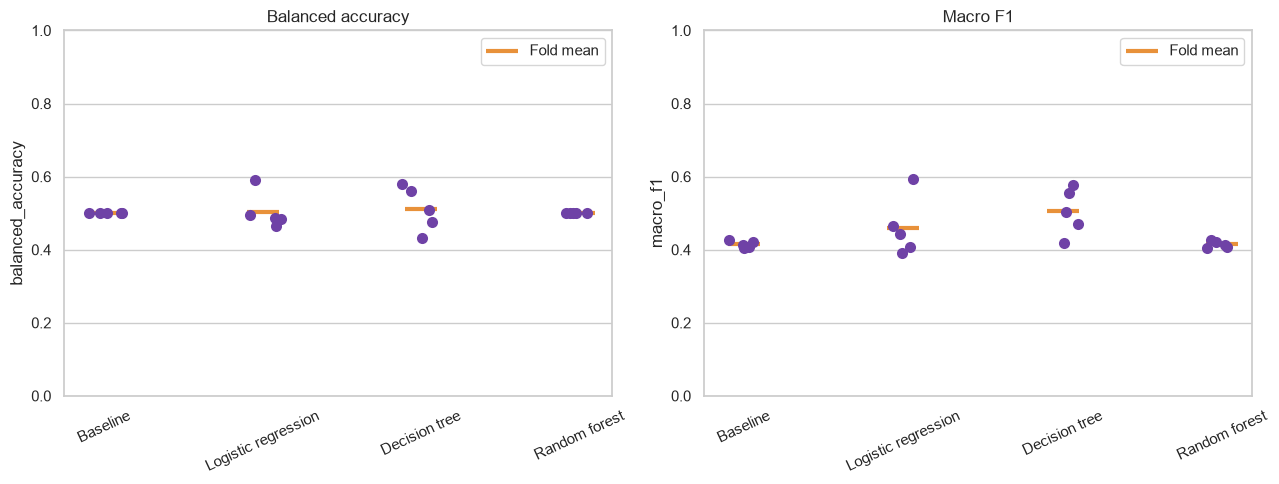

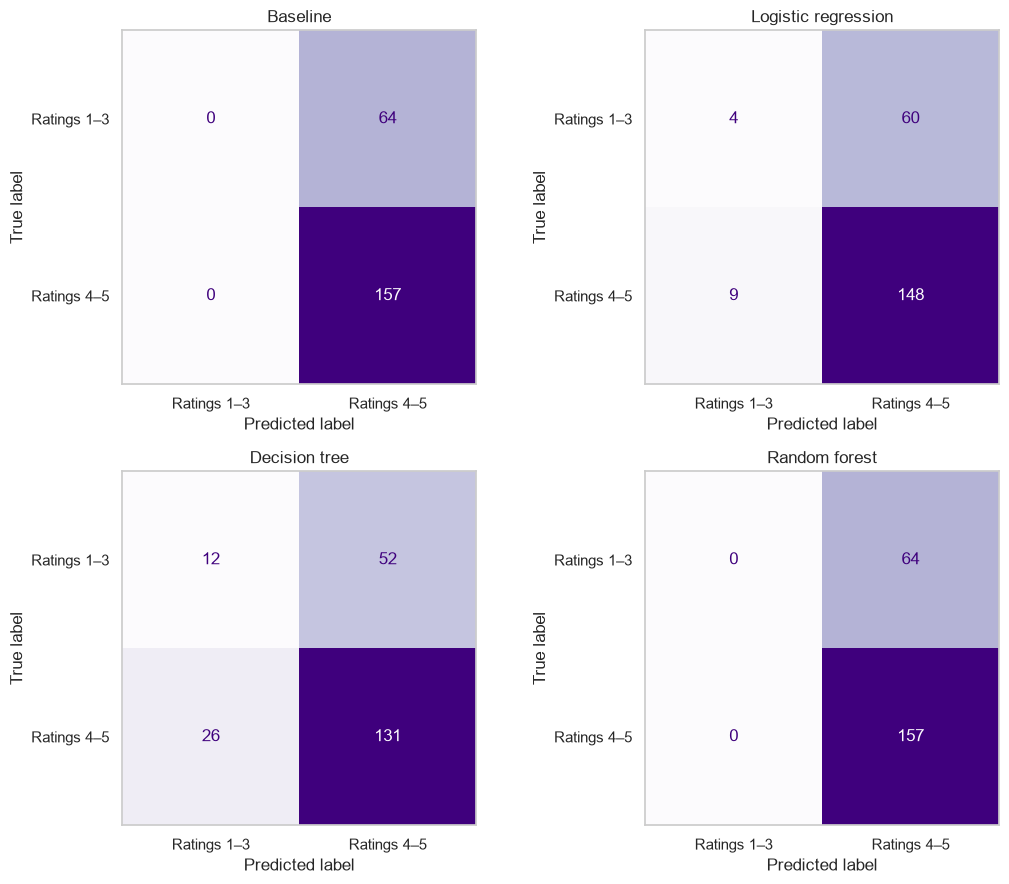

,precision,recall,f1-score,support
Ratings 1–3,0.307692,0.062500,0.103896,64.000000
Ratings 4–5,0.711538,0.942675,0.810959,157.000000
accuracy,0.687783,0.687783,0.687783,0.687783
macro avg,0.509615,0.502588,0.457428,221.000000
weighted avg,0.594588,0.687783,0.606199,221.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric, title in [
    (axes[0], "balanced_accuracy", "Balanced accuracy"),
    (axes[1], "macro_f1", "Macro F1"),
]:
    sns.stripplot(
        data=metrics,
        x="model",
        y=metric,
        order=list(models),
        jitter=0.12,
        color="#6F42A6",
        size=8,
        ax=ax,
    )

    means = metrics.groupby("model")[metric].mean().reindex(models)

    ax.scatter(
        np.arange(len(means)),
        means,
        marker="_",
        s=500,
        color="#E8913A",
        linewidths=3,
        label="Fold mean",
    )

    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.legend()

fig.tight_layout()
fig.savefig(
    MODEL_FIGURES / "model_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

reports = {}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, model_name in zip(axes.flat, models):
    predictions = oof_predictions[model_name]

    matrix = confusion_matrix(
        predictions["actual_class"],
        predictions["predicted_class"],
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        matrix,
        display_labels=["Ratings 1–3", "Ratings 4–5"],
    ).plot(
        ax=ax,
        cmap="Purples",
        colorbar=False,
        values_format="d",
    )

    ax.set_title(model_name)
    ax.grid(False)

    reports[model_name] = pd.DataFrame(
        classification_report(
            predictions["actual_class"],
            predictions["predicted_class"],
            labels=[0, 1],
            target_names=["Ratings 1–3", "Ratings 4–5"],
            output_dict=True,
            zero_division=0,
        )
    ).T

fig.tight_layout()
fig.savefig(
    MODEL_FIGURES / "out_of_fold_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

display(reports[REFERENCE_MODEL])

## 6. Interpret the Reference Model

Calculate permutation importance on held-out folds for the preselected
logistic-regression model.

A positive importance means that shuffling the predictor reduced
balanced accuracy. A value near zero suggests little detectable
predictive contribution in this experiment.

Importance is not a causal effect. Correlated predictors may share or
mask importance. Interpretation is limited if the model performs no
better than the baseline.

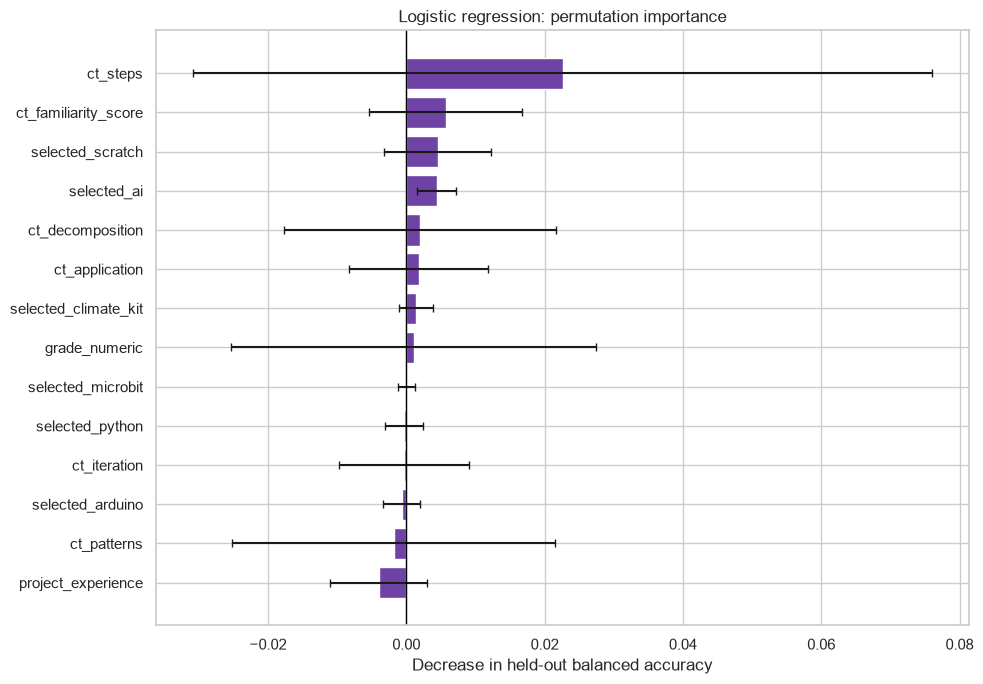

In [7]:
importance_rows = []

for fold, pipeline, test_index in reference_fold_models:
    result = permutation_importance(
        pipeline,
        X.iloc[test_index],
        y.iloc[test_index],
        scoring="balanced_accuracy",
        n_repeats=10,
        random_state=SEED + fold,
        n_jobs=1,
    )

    for feature, importance in zip(
        FEATURES,
        result.importances_mean,
    ):
        importance_rows.append({
            "fold": fold,
            "feature": feature,
            "importance": importance,
        })

importance_by_fold = pd.DataFrame(importance_rows)

importance_summary = (
    importance_by_fold.groupby("feature")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    importance_summary.index,
    importance_summary["mean"],
    xerr=importance_summary["std"].fillna(0),
    color="#6F42A6",
    capsize=3,
)

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Decrease in held-out balanced accuracy")
ax.set_title("Logistic regression: permutation importance")

fig.tight_layout()
fig.savefig(
    MODEL_FIGURES / "logistic_permutation_importance.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

## 7. Save Results and an Exploratory Model

Export the model comparison, fold details, classification reports,
and out-of-fold predictions.

Refit the preselected logistic-regression pipeline using all eligible
records and save it for reproducibility.

This final refitted model has no separate new performance estimate.
Its training predictions must not be reported as validation results.
It remains an exploratory model rather than a deployment recommendation.

In [8]:
with pd.ExcelWriter(
    MODEL_TABLES / "students_model_results.xlsx",
    engine="openpyxl",
) as writer:
    class_table.to_excel(
        writer, sheet_name="Target distribution", index=False
    )

    fold_summary.to_excel(
        writer, sheet_name="Validation folds", index=False
    )

    metrics.to_excel(
        writer, sheet_name="Fold metrics", index=False
    )

    model_summary.to_excel(
        writer, sheet_name="Model comparison", index=False
    )

    importance_summary.to_excel(
        writer, sheet_name="Permutation importance"
    )

    for number, (name, report) in enumerate(reports.items(), start=1):
        report.to_excel(
            writer,
            sheet_name=f"Report {number}",
        )

for model_name, predictions in oof_predictions.items():
    safe_name = model_name.lower().replace(" ", "_")

    predictions.to_csv(
        MODEL_TABLES / f"{safe_name}_oof_predictions.csv",
        index=False,
    )

final_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", clone(models[REFERENCE_MODEL])),
])

final_pipeline.fit(X, y)

model_bundle = {
    "pipeline": final_pipeline,
    "features": FEATURES,
    "numeric_features": numeric_features,
    "binary_features": binary_features,
    "categorical_features": categorical_features,
    "target_definition": {
        0: "STEM-interest ratings 1–3",
        1: "STEM-interest ratings 4–5",
    },
    "model_name": REFERENCE_MODEL,
    "status": "Exploratory; not independently validated after refitting",
}

model_path = MODELS / "students_stem_interest_logistic.joblib"
joblib.dump(model_bundle, model_path)

print("Saved model:", model_path)
print("Saved results:", MODEL_TABLES)
print("Saved figures:", MODEL_FIGURES)

Saved model: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\models\students_stem_interest_logistic.joblib
Saved results: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\tables\student_models
Saved figures: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\figures\student_models


## 8. Generate Predictions for New Standardized Records

New records must use the same feature definitions and coding rules as
the training data.

The model returns a predicted target class and an uncalibrated estimated
probability for ratings 4–5.

These probabilities are model outputs, not guarantees or measures of
a student's ability.

In [9]:
def predict_new_students(new_records, bundle):
    features = bundle["features"]

    missing_columns = set(features) - set(new_records.columns)

    if missing_columns:
        raise ValueError(
            f"Missing predictor columns: {sorted(missing_columns)}"
        )

    prepared = new_records[features].copy()

    for column in (
        bundle["numeric_features"] + bundle["binary_features"]
    ):
        prepared[column] = pd.to_numeric(
            prepared[column],
            errors="raise",
        ).astype(float)

    for column in bundle["categorical_features"]:
        prepared[column] = prepared[column].where(
            prepared[column].notna(),
            np.nan,
        ).astype(object)

    pipeline = bundle["pipeline"]

    predictions = pipeline.predict(prepared)

    positive_column = list(
        pipeline.named_steps["model"].classes_
    ).index(1)

    probabilities = pipeline.predict_proba(
        prepared
    )[:, positive_column]

    return pd.DataFrame(
        {
            "predicted_class": predictions,
            "predicted_group": [
                bundle["target_definition"][int(value)]
                for value in predictions
            ],
            "estimated_probability_ratings_4_5": probabilities,
        },
        index=new_records.index,
    )


# Later, use genuinely new standardized records:
#
# new_students = pd.read_excel("new_students_standardized.xlsx")
# predictions = predict_new_students(new_students, model_bundle)
# display(predictions)

# For now, inspect honest held-out predictions from cross-validation:
display(oof_predictions[REFERENCE_MODEL].head(10))

,response_id,actual_class,predicted_class,probability_class_1
0,S0001,1,1,0.508404
1,S0002,1,1,0.730486
2,S0003,0,1,0.721731
3,S0006,1,1,0.649610
4,S0007,0,1,0.793927
5,S0008,0,1,0.693140
6,S0009,0,1,0.803673
7,S0010,1,1,0.704556
8,S0012,1,1,0.647883
9,S0013,1,1,0.822603


## 9. Results and Interpretation

### Modeling Sample

The experiment included 221 submissions from 42 schools. Twenty of the
241 original submissions were excluded because they were unresolved
duplicate candidates. These exclusions do not establish that all
20 submissions were confirmed duplicates.

Among the included submissions, 157 (71.0%) reported STEM-interest
ratings of 4–5, while 64 (29.0%) reported ratings of 1–3.

Five-fold school-grouped cross-validation was used. Within each fold,
schools in the validation set were excluded from the training set.

### Model Comparison

The following results are the means across the five validation folds.
Standard deviations describe variation across folds, not confidence
intervals.

| Model | Balanced accuracy | Standard deviation | Macro F1 |
|---|---:|---:|---:|
| Majority-class baseline | 0.500 | 0.000 | 0.415 |
| Decision tree | 0.511 | 0.061 | 0.505 |
| Logistic regression | 0.504 | 0.050 | 0.460 |
| Random forest | 0.500 | 0.000 | 0.415 |

The decision tree achieved the highest mean balanced accuracy and
macro F1 among the evaluated models. However, its balanced accuracy
exceeded the baseline by only 0.011, or 1.1 percentage points.

Logistic regression also performed close to the baseline. The random
forest matched the baseline on the reported metrics.

These results do not demonstrate a clear, reliable improvement in
balanced accuracy over the majority-class baseline. The decision tree's
higher macro F1 indicates a different balance of errors, but does not
by itself establish strong predictive performance.

### Logistic-Regression Errors

The pooled out-of-fold logistic-regression results showed:

- Overall accuracy: 68.8%.
- Recall for ratings 1–3: 6.25%.
- Recall for ratings 4–5: 94.27%.

The model correctly identified only 4 of the 64 submissions with ratings
1–3, compared with 148 of the 157 submissions with ratings 4–5.

Therefore, its predictions strongly favored the larger class.
Predicting ratings 4–5 for every submission would achieve approximately
71.0% overall accuracy, exceeding the logistic-regression accuracy.

This illustrates why overall accuracy alone is insufficient for this
dataset.

### Feature-Importance Interpretation

Permutation importance should be interpreted cautiously because the
reference model performed close to the baseline.

The importance chart describes how the fitted model used the available
predictors. It does not establish that those variables cause STEM
interest or that they are reliable predictors in other populations.

### Limitations

The experiment used a small sample, self-reported survey responses,
and a target created by grouping the original five ratings into two
classes. This grouping removes some information.

Excluding unresolved duplicate candidates may affect the composition
of the modeling sample. The results also come from one five-fold
partition and do not constitute independent external validation.

The models predict reported interest at the time of the survey.
They do not predict future STEM careers, measure student ability,
or establish the effect of the event.

### Conclusion

Under the current predictor set, model settings, target definition,
and school-grouped validation design, the evaluated models showed
limited ability to distinguish STEM-interest ratings 1–3 from 4–5.

The decision tree had the strongest reported comparative scores,
but the small balanced-accuracy improvement is insufficient to
recommend practical use.

The descriptive survey analysis remains useful for understanding
student interests and prior experiences. The prediction models
should remain exploratory.